In [1]:
import pandas as pd
import matplotlib.pyplot as plt

path = "../data/raw/online_retail_II.xlsx"
xls = pd.ExcelFile(path)
xls.sheet_names

['Year 2009-2010', 'Year 2010-2011']

In [2]:
sheets = pd.read_excel(path, sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)
print("Selesai dibaca")

Selesai dibaca


In [3]:
df.shape

(1067371, 8)

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df = df.rename(columns={"invoicedate": "invoice_date"})
df.columns

Index(['invoice', 'stockcode', 'description', 'quantity', 'invoice_date',
       'price', 'customer_id', 'country'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  object        
 1   stockcode     1067371 non-null  object        
 2   description   1062989 non-null  object        
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   price         1067371 non-null  float64       
 6   customer_id   824364 non-null   float64       
 7   country       1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [7]:
df["invoice"] = df["invoice"].astype(str)
df["stockcode"] = df["stockcode"].astype(str)

In [8]:
kosong = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persen": (df.isna().mean() * 100).round(1),
})
kosong

,jumlah_kosong,persen
invoice,0,0.0
stockcode,0,0.0
description,4382,0.4
quantity,0,0.0
invoice_date,0,0.0
price,0,0.0
customer_id,243007,22.8
country,0,0.0


In [9]:
print("Baris dobel:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(["invoice", "stockcode"]).head(6)

Baris dobel: 34335


,invoice,stockcode,description,quantity,invoice_date,price,customer_id,country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [10]:
df[["quantity", "price"]].describe()

,quantity,price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


In [11]:
negatif = df[df["quantity"] < 0]
print("Baris quantity negatif:", len(negatif))
negatif.head()

Baris quantity negatif: 22950


,invoice,stockcode,description,quantity,invoice_date,price,customer_id,country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [12]:
batal = df["invoice"].str.startswith("C")
print("Baris pembatalan:", batal.sum())
print("Quantity negatif yang BUKAN pembatalan:", ((df["quantity"] < 0) & ~batal).sum())
df[(df["quantity"] < 0) & ~batal].head()

Baris pembatalan: 19494
Quantity negatif yang BUKAN pembatalan: 3457


,invoice,stockcode,description,quantity,invoice_date,price,customer_id,country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


In [13]:
print("Harga = 0 :", (df["price"] == 0).sum())
print("Harga < 0 :", (df["price"] < 0).sum())
df[df["price"] < 0]

Harga = 0 : 6202
Harga < 0 : 5


,invoice,stockcode,description,quantity,invoice_date,price,customer_id,country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [14]:
bukan_produk = ~df["stockcode"].str.match(r"^\d{5}")
print("Baris dengan kode bukan pola produk:", bukan_produk.sum())
df.loc[bukan_produk, ["stockcode", "description"]].value_counts().head(20)

Baris dengan kode bukan pola produk: 6093


stockcode     description                        
POST          POSTAGE                                2115
DOT           DOTCOM POSTAGE                         1444
M             Manual                                 1421
C2            CARRIAGE                                279
D             Discount                                177
S             SAMPLES                                 104
BANK CHARGES  Bank Charges                             96
AMAZONFEE     AMAZON FEE                               43
ADJUST        Adjustment by john on 26/01/2010 16      38
DCGS0058      MISO PRETTY  GUM                         30
gift_0001_20  Dotcomgiftshop Gift Voucher £20.00       26
ADJUST        Adjustment by john on 26/01/2010 17      26
gift_0001_30  Dotcomgiftshop Gift Voucher £30.00       24
DCGSSGIRL     GIRLS PARTY BAG                          23
DCGSSBOY      BOYS PARTY BAG                           21
PADS          PADS TO MATCH ALL CUSHIONS               19
CRUK          CRUK Com

In [15]:
print("Rentang tanggal :", df["invoice_date"].min(), "s.d.", df["invoice_date"].max())
print("Pelanggan unik  :", df["customer_id"].nunique())
print("Produk unik     :", df["stockcode"].nunique())
print("Negara          :", df["country"].nunique())
df["country"].value_counts().head(10)

Rentang tanggal : 2009-12-01 07:45:00 s.d. 2011-12-09 12:50:00
Pelanggan unik  : 5942
Produk unik     : 5305
Negara          : 43


country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64

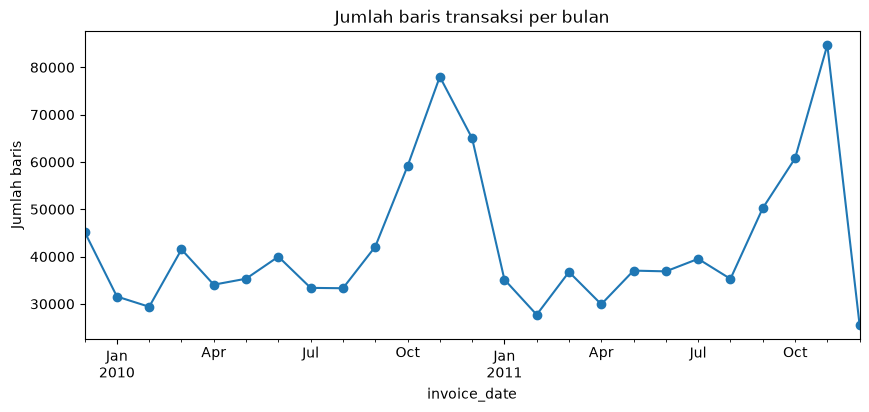

In [16]:
per_bulan = df.set_index("invoice_date").resample("MS").size()

fig, ax = plt.subplots(figsize=(10, 4))
per_bulan.plot(ax=ax, marker="o")
ax.set_title("Jumlah baris transaksi per bulan")
ax.set_ylabel("Jumlah baris")
plt.show()

count    1.044421e+06
mean     1.117612e+01
std      1.294560e+02
min      1.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: quantity, dtype: float64


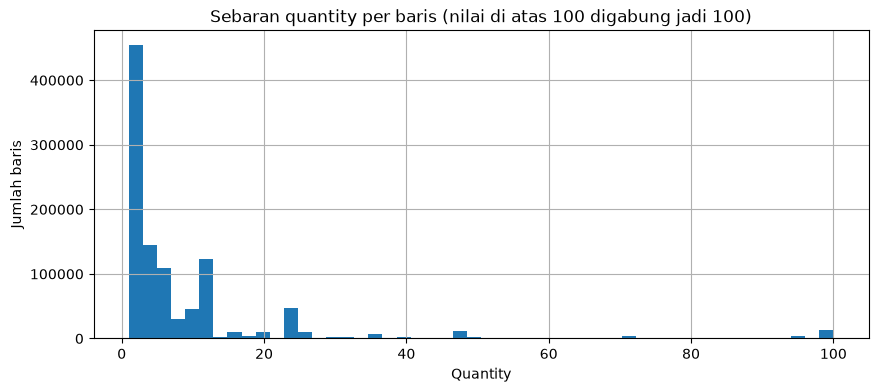

In [17]:
qty = df.loc[df["quantity"] > 0, "quantity"]
print(qty.describe())

fig, ax = plt.subplots(figsize=(10, 4))
qty.clip(upper=100).hist(bins=50, ax=ax)
ax.set_title("Sebaran quantity per baris (nilai di atas 100 digabung jadi 100)")
ax.set_xlabel("Quantity")
ax.set_ylabel("Jumlah baris")
plt.show()

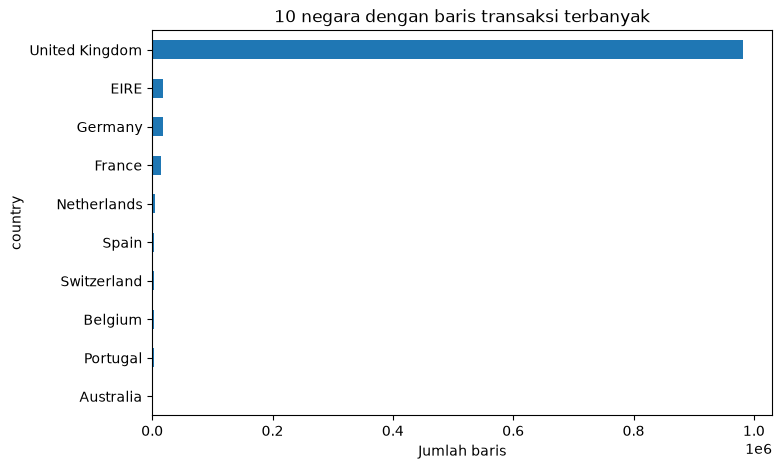

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
df["country"].value_counts().head(10).sort_values().plot(kind="barh", ax=ax)
ax.set_title("10 negara dengan baris transaksi terbanyak")
ax.set_xlabel("Jumlah baris")
plt.show()

In [19]:
df["customer_id"] = df["customer_id"].astype("Int64")
df["description"] = df["description"].astype("string")
df.to_parquet("../data/processed/transactions.parquet", index=False)
print("Tersimpan")

Tersimpan
